# Monitoreo de un modelo de fraude financiero

**Hector Americo Torres Huamani · Proyecto de portafolio**

Basado en [Monitoring a Financial Fraud Detection Model, DataCamp 2104](https://app.datacamp.com/learn/projects/2104). El escenario y los datos proceden de DataCamp. Este notebook presenta la solución, una auditoría ampliada y la interpretación de los resultados.

**Objetivo:** identificar meses con alertas conjuntas de exactitud estimada y observada, la variable con deriva más asociada al cambio de rendimiento y el importe medio mensual que activa una alerta.

**Estado:** solución aprobada por DataCamp el 9 de noviembre de 2026, 1 500 XP. [Evidencia](evidence/datacamp_aprobado.jpg) · [Reporte](docs/Reporte_final.pdf) · [Guía del código](docs/Guia_codigo_paso_a_paso.pdf).

Para leer los resultados basta abrir este archivo en GitHub. Para recalcularlos, utiliza Python 3.11, instala `requirements.txt` y descarga los datos siguiendo `data/README.md`. Ejecuta desde la raíz del repositorio.

Se conserva el modelo ya puntuado. El análisis de correlación orienta el diagnóstico y no demuestra causalidad.

## 1. Preparación y contexto
Poundbank necesita vigilar un detector de fraude después del despliegue. `reference.csv` es la base de test
para ajustar los monitores; `analysis.csv` simula producción. Las entradas son minutos desde login,
importe GBP, tipo de operación, primera transacción y antigüedad. La fecha ordena los bloques mensuales.
`is_fraud` es la verdad observada; `predicted_fraud_proba` y `predicted_fraud` son las salidas suministradas.

Se usa NannyML con telemetría desactivada. La semilla fija facilita reproducir la calibración.

In [1]:
"""Proyecto 2104: ejecucion reproducible sobre los CSV originales de DataCamp."""
from pathlib import Path
import calendar
import hashlib
import json
import platform
import warnings
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr, ks_2samp, chi2_contingency
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import nannyml as nml
nml.disable_usage_logging()

ROOT = Path.cwd()
assert (ROOT/'data/reference.csv').exists(), 'Abre el notebook desde la carpeta del proyecto'
FEATURES = ['time_since_login_min', 'transaction_amount', 'transaction_type',
            'is_first_transaction', 'user_tenure_months']
COMMON = dict(timestamp_column_name='timestamp', y_true='is_fraud',
    y_pred='predicted_fraud', y_pred_proba='predicted_fraud_proba',
    problem_type='classification_binary', chunk_period='M', metrics=['accuracy'])


from IPython.display import display, Image


## 2. Auditoría antes de calcular
Se validan dominios, probabilidades, fechas, nulos y separación temporal. No se borran transacciones.
Los nulos de tipo de transacción se conservan para la primera prueba y se representan explícitamente
en la segunda. Las huellas SHA-256 permiten comprobar que los datos de entrada no cambiaron.

In [2]:
def save_json(path, obj):
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

def flatten(result):
    df = result.to_df().copy()
    df.columns = ['__'.join(map(str, c)) if isinstance(c, tuple) else c for c in df.columns]
    return df

def load_data():
    data, audit = {}, {}
    for name in ['reference', 'analysis']:
        path = ROOT/'data'/f'{name}.csv'
        df = pd.read_csv(path, parse_dates=['timestamp'])
        required = FEATURES + ['timestamp','is_fraud','predicted_fraud','predicted_fraud_proba']
        assert set(df) == set(required), f'Esquema inesperado: {name}'
        assert df.timestamp.notna().all(), 'Fechas nulas'
        for col in ['is_fraud', 'predicted_fraud']:
            assert df[col].notna().all() and set(df[col].unique()) <= {0,1}
            df[col] = df[col].astype(int)
        assert df.predicted_fraud_proba.between(0,1).all()
        for col in ['time_since_login_min','transaction_amount','user_tenure_months']:
            assert np.isfinite(df[col]).all() and (df[col] >= 0).all()
        audit[name] = dict(rows=len(df), columns=len(df.columns),
            first=str(df.timestamp.min()), last=str(df.timestamp.max()),
            missing=df.isna().sum().to_dict(), duplicate_rows=int(df.duplicated().sum()),
            duplicate_timestamps=int(df.timestamp.duplicated().sum()),
            sorted=bool(df.timestamp.is_monotonic_increasing),
            fraud_rate=float(df.is_fraud.mean()), sha256=hashlib.sha256(path.read_bytes()).hexdigest())
        data[name] = df.sort_values('timestamp').reset_index(drop=True)
    assert data['reference'].timestamp.max() < data['analysis'].timestamp.min(), 'Solapamiento temporal'
    return data['reference'], data['analysis'], audit

def monthly_metrics(df, period):
    records = []
    for month, g in df.groupby(df.timestamp.dt.to_period('M'), sort=True):
        y, pred, proba = g.is_fraud, g.predicted_fraud, g.predicted_fraud_proba
        tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
        n, acc = len(g), accuracy_score(y,pred)
        z=1.959963984540054
        center=(acc+z*z/(2*n))/(1+z*z/n)
        half=z*np.sqrt(acc*(1-acc)/n+z*z/(4*n*n))/(1+z*z/n)
        bins=pd.cut(proba,np.linspace(0,1,11),include_lowest=True)
        cal=pd.DataFrame({'p':proba,'y':y,'bin':bins}).groupby('bin',observed=True).agg(p=('p','mean'),y=('y','mean'),n=('y','size'))
        records.append(dict(month=str(month),period=period,n=n,fraud_rate=y.mean(),
            accuracy=acc,accuracy_ci_low=center-half,accuracy_ci_high=center+half,
            precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),
            specificity=tn/(tn+fp),f1=f1_score(y,pred,zero_division=0),
            roc_auc=roc_auc_score(y,proba),average_precision=average_precision_score(y,proba),
            brier=brier_score_loss(y,proba),ece=float((abs(cal.p-cal.y)*cal.n/n).sum()),
            tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
            amount_mean=g.transaction_amount.mean(),amount_median=g.transaction_amount.median(),
            amount_p95=g.transaction_amount.quantile(.95),
            fn_amount=g.loc[(y==1)&(pred==0),'transaction_amount'].sum(),
            missing_type_rate=g.transaction_type.isna().mean(),
            login_under_1_rate=(g.time_since_login_min<1).mean(),
            score_05_disagreements=int(((proba>=.5).astype(int)!=pred).sum())))
    return pd.DataFrame(records)

reference,analysis,audit=load_data()
output=ROOT/'output'
output.mkdir(exist_ok=True)
save_json(output/'data_audit.json',audit)
display(pd.DataFrame(audit).T[['rows','columns','first','last','fraud_rate']])
display(pd.DataFrame({k:v['missing'] for k,v in audit.items()}))


,rows,columns,first,last,fraud_rate
reference,50207,9,2018-01-01 00:00:00,2018-10-31 23:56:09.312000,0.499751
analysis,39967,9,2018-11-01 00:04:52.464000,2019-06-30 23:56:25.296000,0.499387


,reference,analysis
timestamp,0,0
time_since_login_min,0,0
transaction_amount,0,0
transaction_type,3052,2453
is_first_transaction,0,0
user_tenure_months,0,0
is_fraud,0,0
predicted_fraud_proba,0,0
predicted_fraud,0,0


## 3. Análisis previo
Se calcula la exactitud y también precisión, recall, F1, ROC-AUC, average precision,
Brier y calibración por bins. La exactitud no resume por sí sola los errores del detector.
Los intervalos Wilson son aproximaciones bajo independencia y no son umbrales de alerta.
Se conservan las etiquetas predichas: reemplazarlas por un umbral 0,50 cambiaría el problema.

In [3]:
monthly=pd.concat([monthly_metrics(reference,'reference'),monthly_metrics(analysis,'analysis')],ignore_index=True)
monthly.to_csv(output/'monthly_metrics.csv',index=False)
display(monthly[['month','n','accuracy','precision','recall','amount_mean','missing_type_rate']])

,month,n,accuracy,precision,recall,amount_mean,missing_type_rate
0,2018-01,5120,0.947070,0.960991,0.931102,2968.145410,0.056055
1,2018-02,4625,0.939892,0.953246,0.923077,2974.408930,0.062919
2,2018-03,5119,0.944130,0.958882,0.929207,2940.643426,0.056847
3,2018-04,4955,0.944299,0.958004,0.929407,2956.591100,0.057518
4,2018-05,5120,0.938672,0.955547,0.921591,2942.334297,0.063672
5,2018-06,4954,0.944489,0.953820,0.932294,2993.209851,0.066209
6,2018-07,5120,0.944727,0.956837,0.930926,2987.636445,0.064258
7,2018-08,5120,0.944922,0.956193,0.933152,2978.099297,0.056250
8,2018-09,4954,0.945095,0.962303,0.927716,2970.678260,0.060355
9,2018-10,5120,0.942578,0.952495,0.931667,2937.478730,0.064062


## 4. Primera prueba
Los monitores se ajustan solo sobre referencia. CBPE estima sin usar etiquetas de producción;
PerformanceCalculator las usa después para contrastar el resultado. Se combinan las alertas con AND.
KS se aplica a entradas continuas y chi-cuadrado a categóricas. La media mensual tiene sus propios límites.

En la versión inicial el ranking usa referencia y producción juntas. Esto se revisa a continuación.

In [4]:
def run_monitoring(reference, analysis, out, improved=False):
    out.mkdir(parents=True,exist_ok=True)
    np.random.seed(42)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        estimator=nml.CBPE(**COMMON).fit(reference)
        # No usar las etiquetas de produccion para estimar el rendimiento.
        estimated=estimator.estimate(analysis.drop(columns='is_fraud'))
        calculator=nml.PerformanceCalculator(**COMMON).fit(reference)
        realized=calculator.calculate(analysis)
        drift_ref, drift_ana = reference.copy(),analysis.copy()
        if improved:
            for df in [drift_ref,drift_ana]:
                df['transaction_type']=df.transaction_type.fillna('__MISSING__')
        drift=nml.UnivariateDriftCalculator(column_names=FEATURES,
            timestamp_column_name='timestamp', chunk_period='M',
            continuous_methods=['kolmogorov_smirnov'], categorical_methods=['chi2'],
            treat_as_categorical=['transaction_type','is_first_transaction']).fit(drift_ref).calculate(drift_ana)
        avg=nml.SummaryStatsAvgCalculator(column_names=['transaction_amount'],
            timestamp_column_name='timestamp',chunk_period='M').fit(reference).calculate(analysis)
        ranker=nml.CorrelationRanker().fit(realized.filter(period='reference'))
        ranking_all=ranker.rank(drift,realized,only_drifting=True)
        ranking_analysis=ranker.rank(drift.filter(period='analysis'),realized.filter(period='analysis'),only_drifting=True)
    for name,result in [('estimated',estimated),('realized',realized),('drift',drift),('average',avg)]:
        flatten(result).to_csv(out/f'{name}.csv',index=False)
    ranking_all.to_csv(out/'ranking_all.csv',index=False)
    ranking_analysis.to_csv(out/'ranking_analysis.csv',index=False)
    e,r=estimated.filter(period='analysis').to_df(),realized.filter(period='analysis').to_df()
    assert e[('chunk','key')].tolist()==r[('chunk','key')].tolist(), 'Meses no alineados'
    perf=pd.DataFrame({'month':e[('chunk','key')].values,
        'estimated_accuracy':e[('accuracy','value')].values,
        'realized_accuracy':r[('accuracy','value')].values,
        'estimated_alert':e[('accuracy','alert')].values,
        'realized_alert':r[('accuracy','alert')].values,
        'estimated_lower':e[('accuracy','lower_threshold')].values,
        'estimated_upper':e[('accuracy','upper_threshold')].values,
        'realized_lower':r[('accuracy','lower_threshold')].values,
        'realized_upper':r[('accuracy','upper_threshold')].values})
    perf['joint_alert']=perf.estimated_alert & perf.realized_alert
    perf['absolute_estimation_error']=abs(perf.estimated_accuracy-perf.realized_accuracy)
    perf.to_csv(out/'performance_comparison.csv',index=False)
    monthly=monthly_metrics(analysis,'analysis')
    np.testing.assert_allclose(perf.realized_accuracy,monthly.accuracy,rtol=0,atol=1e-12)
    a=avg.filter(period='analysis').to_df()
    np.testing.assert_allclose(a[('transaction_amount','value')],monthly.amount_mean,rtol=1e-12)
    alerted=a.loc[a[('transaction_amount','alert')]]
    amounts=[dict(month=str(row[('chunk','key')]),mean=float(row[('transaction_amount','value')]),
        lower_threshold=float(row[('transaction_amount','lower_threshold')]),
        upper_threshold=float(row[('transaction_amount','upper_threshold')])) for _,row in alerted.iterrows()]
    chosen=ranking_analysis if improved else ranking_all
    months=[f'{calendar.month_name[pd.Period(m).month].lower()}_{pd.Period(m).year}' for m in perf.loc[perf.joint_alert,'month']]
    answer=dict(months_with_performance_alerts=months,
        highest_correlation_feature=None if chosen.empty else chosen.iloc[0].column_name,
        alert_avg_transaction_amount=round(amounts[0]['mean'],4) if len(amounts)==1 else None,
        amount_alerts=amounts,needs_calibration=bool(estimator.needs_calibration),
        estimation_mae=float(perf.absolute_estimation_error.mean()),
        ranking_scope='analysis' if improved else 'reference_and_analysis',
        checks=['exactitud coincide con sklearn (1e-12)','importe medio coincide con pandas (1e-12)',
                'estimacion sin etiquetas de produccion','meses alineados'])
    save_json(out/'answers.json',answer)
    save_json(out/'warnings.json',sorted(set(str(w.message) for w in caught)))
    return answer,perf,drift,realized

v1,perf_v1,drift_v1,realized_v1=run_monitoring(reference,analysis,output/'v1',improved=False)
print(json.dumps(v1,indent=2,ensure_ascii=False))
display(perf_v1)
display(pd.read_csv(output/'v1/ranking_all.csv'))

{
  "months_with_performance_alerts": [
    "april_2019",
    "may_2019",
    "june_2019"
  ],
  "highest_correlation_feature": "time_since_login_min",
  "alert_avg_transaction_amount": 3069.8184,
  "amount_alerts": [
    {
      "month": "2019-06",
      "mean": 3069.8183551967713,
      "lower_threshold": 2908.4340259731684,
      "upper_threshold": 3021.411123303728
    }
  ],
  "needs_calibration": true,
  "estimation_mae": 0.003223742336341595,
  "ranking_scope": "reference_and_analysis",
  "checks": [
    "exactitud coincide con sklearn (1e-12)",
    "importe medio coincide con pandas (1e-12)",
    "estimacion sin etiquetas de produccion",
    "meses alineados"
  ]
}


,month,estimated_accuracy,realized_accuracy,estimated_alert,realized_alert,estimated_lower,estimated_upper,realized_lower,realized_upper,joint_alert,absolute_estimation_error
0,2018-11,0.941947,0.942684,False,False,0.936367,0.950808,0.936367,0.950808,False,0.000738
1,2018-12,0.943251,0.941004,False,False,0.936367,0.950808,0.936367,0.950808,False,0.002247
2,2019-01,0.945452,0.951758,False,True,0.936367,0.950808,0.936367,0.950808,False,0.006306
3,2019-02,0.944608,0.943123,False,False,0.936367,0.950808,0.936367,0.950808,False,0.001485
4,2019-03,0.943735,0.940039,False,False,0.936367,0.950808,0.936367,0.950808,False,0.003696
5,2019-04,0.911049,0.914632,True,True,0.936367,0.950808,0.936367,0.950808,True,0.003583
6,2019-05,0.910242,0.915413,True,True,0.936367,0.950808,0.936367,0.950808,True,0.005171
7,2019-06,0.911663,0.914228,True,True,0.936367,0.950808,0.936367,0.950808,True,0.002565


,column_name,pearsonr_correlation,pearsonr_pvalue,has_drifted,rank
0,time_since_login_min,0.952925,1.045775e-09,True,1
1,transaction_amount,0.626235,5.427712e-03,True,2
2,is_first_transaction,0.054255,8.306916e-01,True,3
3,user_tenure_months,-0.100547,6.913911e-01,True,4
4,transaction_type,-0.186569,4.585328e-01,True,5


## 5. Revisión de la primera prueba
Se comprueba que el resultado observado coincide con scikit-learn y la media con pandas (1e-12).
Enero tiene alerta por exactitud observada alta, pero no alerta conjunta. No es deterioro.

Mejoras: limitar el ranking principal a producción, tratar la ausencia de `transaction_type` como categoría,
comprobar Spearman y exclusión de cada mes, y ajustar los contrastes múltiples con BH.
El ranking mide asociación con el cambio **absoluto** respecto al promedio de referencia.
Ocho meses y la dependencia temporal limitan la interpretación de las p-valores.

In [5]:
def bh_adjust(p):
    p=np.asarray(p,float); idx=np.argsort(p); adj=np.minimum.accumulate((p[idx]*len(p)/np.arange(1,len(p)+1))[::-1])[::-1]
    out=np.empty(len(p)); out[idx]=np.minimum(adj,1); return out

def robustness(reference,analysis,drift,realized,out):
    d=drift.filter(period='analysis').to_df(); r=realized.filter(period='analysis').to_df()
    base=realized.filter(period='reference').to_df()[('accuracy','value')].mean()
    change=abs(r[('accuracy','value')].to_numpy()-base)
    ranks=[]
    for feature in FEATURES:
        method='chi2' if feature in ['transaction_type','is_first_transaction'] else 'kolmogorov_smirnov'
        values=d[(feature,method,'value')].to_numpy()
        pc=pearsonr(values,change); sc=spearmanr(values,change)
        loo=[pearsonr(np.delete(values,i),np.delete(change,i)).statistic for i in range(len(change))]
        ranks.append(dict(feature=feature,pearson_r=pc.statistic,pearson_p=pc.pvalue,
            spearman_r=sc.statistic,spearman_p=sc.pvalue,loo_min=min(loo),loo_max=max(loo),months=len(change)))
    rank=pd.DataFrame(ranks);rank['pearson_p_bh']=bh_adjust(rank.pearson_p)
    rank.sort_values('pearson_r',ascending=False).to_csv(out/'correlation_robustness.csv',index=False)
    tests=[]
    for month,g in analysis.groupby(analysis.timestamp.dt.to_period('M'),sort=True):
        for f in FEATURES:
            if f in ['transaction_type','is_first_transaction']:
                x=reference[f].fillna('__MISSING__').astype(str).value_counts()
                y=g[f].fillna('__MISSING__').astype(str).value_counts()
                counts=pd.concat([x,y],axis=1).fillna(0).T.to_numpy()
                stat,p,_,_=chi2_contingency(counts,correction=False)
            else:
                stat,p=ks_2samp(reference[f],g[f])
            tests.append(dict(month=str(month),feature=f,statistic=stat,p_value=p))
    tests=pd.DataFrame(tests);tests['p_bh_40_tests']=bh_adjust(tests.p_value)
    tests['significant_bh_005']=tests.p_bh_40_tests<.05
    tests.to_csv(out/'drift_multiple_tests.csv',index=False)

def additional_evidence(reference,analysis,out):
    ref,ana=reference.copy(),analysis.copy()
    ref['phase']='referencia'
    ana['phase']=np.where(ana.timestamp<'2019-04-01','produccion_estable','produccion_alerta')
    df=pd.concat([ref,ana],ignore_index=True)
    df['error']=df.is_fraud!=df.predicted_fraud
    df['early']=df.time_since_login_min<1
    df['fn']=(df.is_fraud==1)&(df.predicted_fraud==0)
    df['fp']=(df.is_fraud==0)&(df.predicted_fraud==1)
    df.groupby('phase').agg(n=('is_fraud','size'),fraud_rate=('is_fraud','mean'),
        error_rate=('error','mean'),fn=('fn','sum'),fp=('fp','sum'),early_count=('early','sum'),
        early_rate=('early','mean'),amount_mean=('transaction_amount','mean')).to_csv(out/'phase_summary.csv')
    df.groupby(['phase','is_fraud']).agg(n=('is_fraud','size'),amount_mean=('transaction_amount','mean'),
        early_rate=('early','mean'),login_mean=('time_since_login_min','mean')).to_csv(out/'segments.csv')
    threshold_check={str(t):int(((df.predicted_fraud_proba>=t).astype(int)!=df.predicted_fraud).sum())
                     for t in [.5,.6,.65,.66,.7]}
    save_json(out/'prediction_threshold_check.json',dict(disagreements=threshold_check,
        note='0.65 reproduce las etiquetas suministradas. No se optimizo ni cambio el modelo.'))

final,performance,drift,realized=run_monitoring(reference,analysis,output/'final',improved=True)
robustness(reference,analysis,drift,realized,output/'final')
additional_evidence(reference,analysis,output/'final')
assert v1['months_with_performance_alerts']==final['months_with_performance_alerts']
assert v1['highest_correlation_feature']==final['highest_correlation_feature']
assert v1['alert_avg_transaction_amount']==final['alert_avg_transaction_amount']
np.testing.assert_allclose(perf_v1.estimated_accuracy,performance.estimated_accuracy,atol=1e-12,rtol=0)
display(pd.read_csv(output/'final/correlation_robustness.csv'))
display(pd.read_csv(output/'final/drift_multiple_tests.csv').query('significant_bh_005'))

,feature,pearson_r,pearson_p,spearman_r,spearman_p,loo_min,loo_max,months,pearson_p_bh
0,time_since_login_min,0.970370,0.000064,0.523810,0.182721,0.960658,0.987852,8,0.000318
1,transaction_amount,0.545766,0.161733,0.309524,0.455645,0.264934,0.808331,8,0.404333
2,is_first_transaction,-0.214904,0.609289,-0.023810,0.955374,-0.380670,-0.046948,8,0.609289
3,transaction_type,-0.238077,0.570186,0.261905,0.530923,-0.446651,-0.089229,8,0.609289
4,user_tenure_months,-0.402382,0.323016,-0.285714,0.492726,-0.538003,-0.257305,8,0.538359


,month,feature,statistic,p_value,p_bh_40_tests,significant_bh_005
14,2019-01,user_tenure_months,0.025002,5.902802e-03,4.722242e-02,True
25,2019-04,time_since_login_min,0.050268,2.413704e-10,3.218272e-09,True
30,2019-05,time_since_login_min,0.049956,1.631806e-10,3.218272e-09,True
35,2019-06,time_since_login_min,0.050964,1.277323e-10,3.218272e-09,True
36,2019-06,transaction_amount,0.036341,1.305146e-05,1.305146e-04,True


## 6. Visualización y diagnóstico
Las figuras separan referencia y producción. La primera muestra rendimiento y estadísticas del importe;
la segunda contrasta la desaparición casi total de operaciones rápidas con los falsos negativos.
La segmentación por clase comprueba si el cambio se limita realmente al fraude.

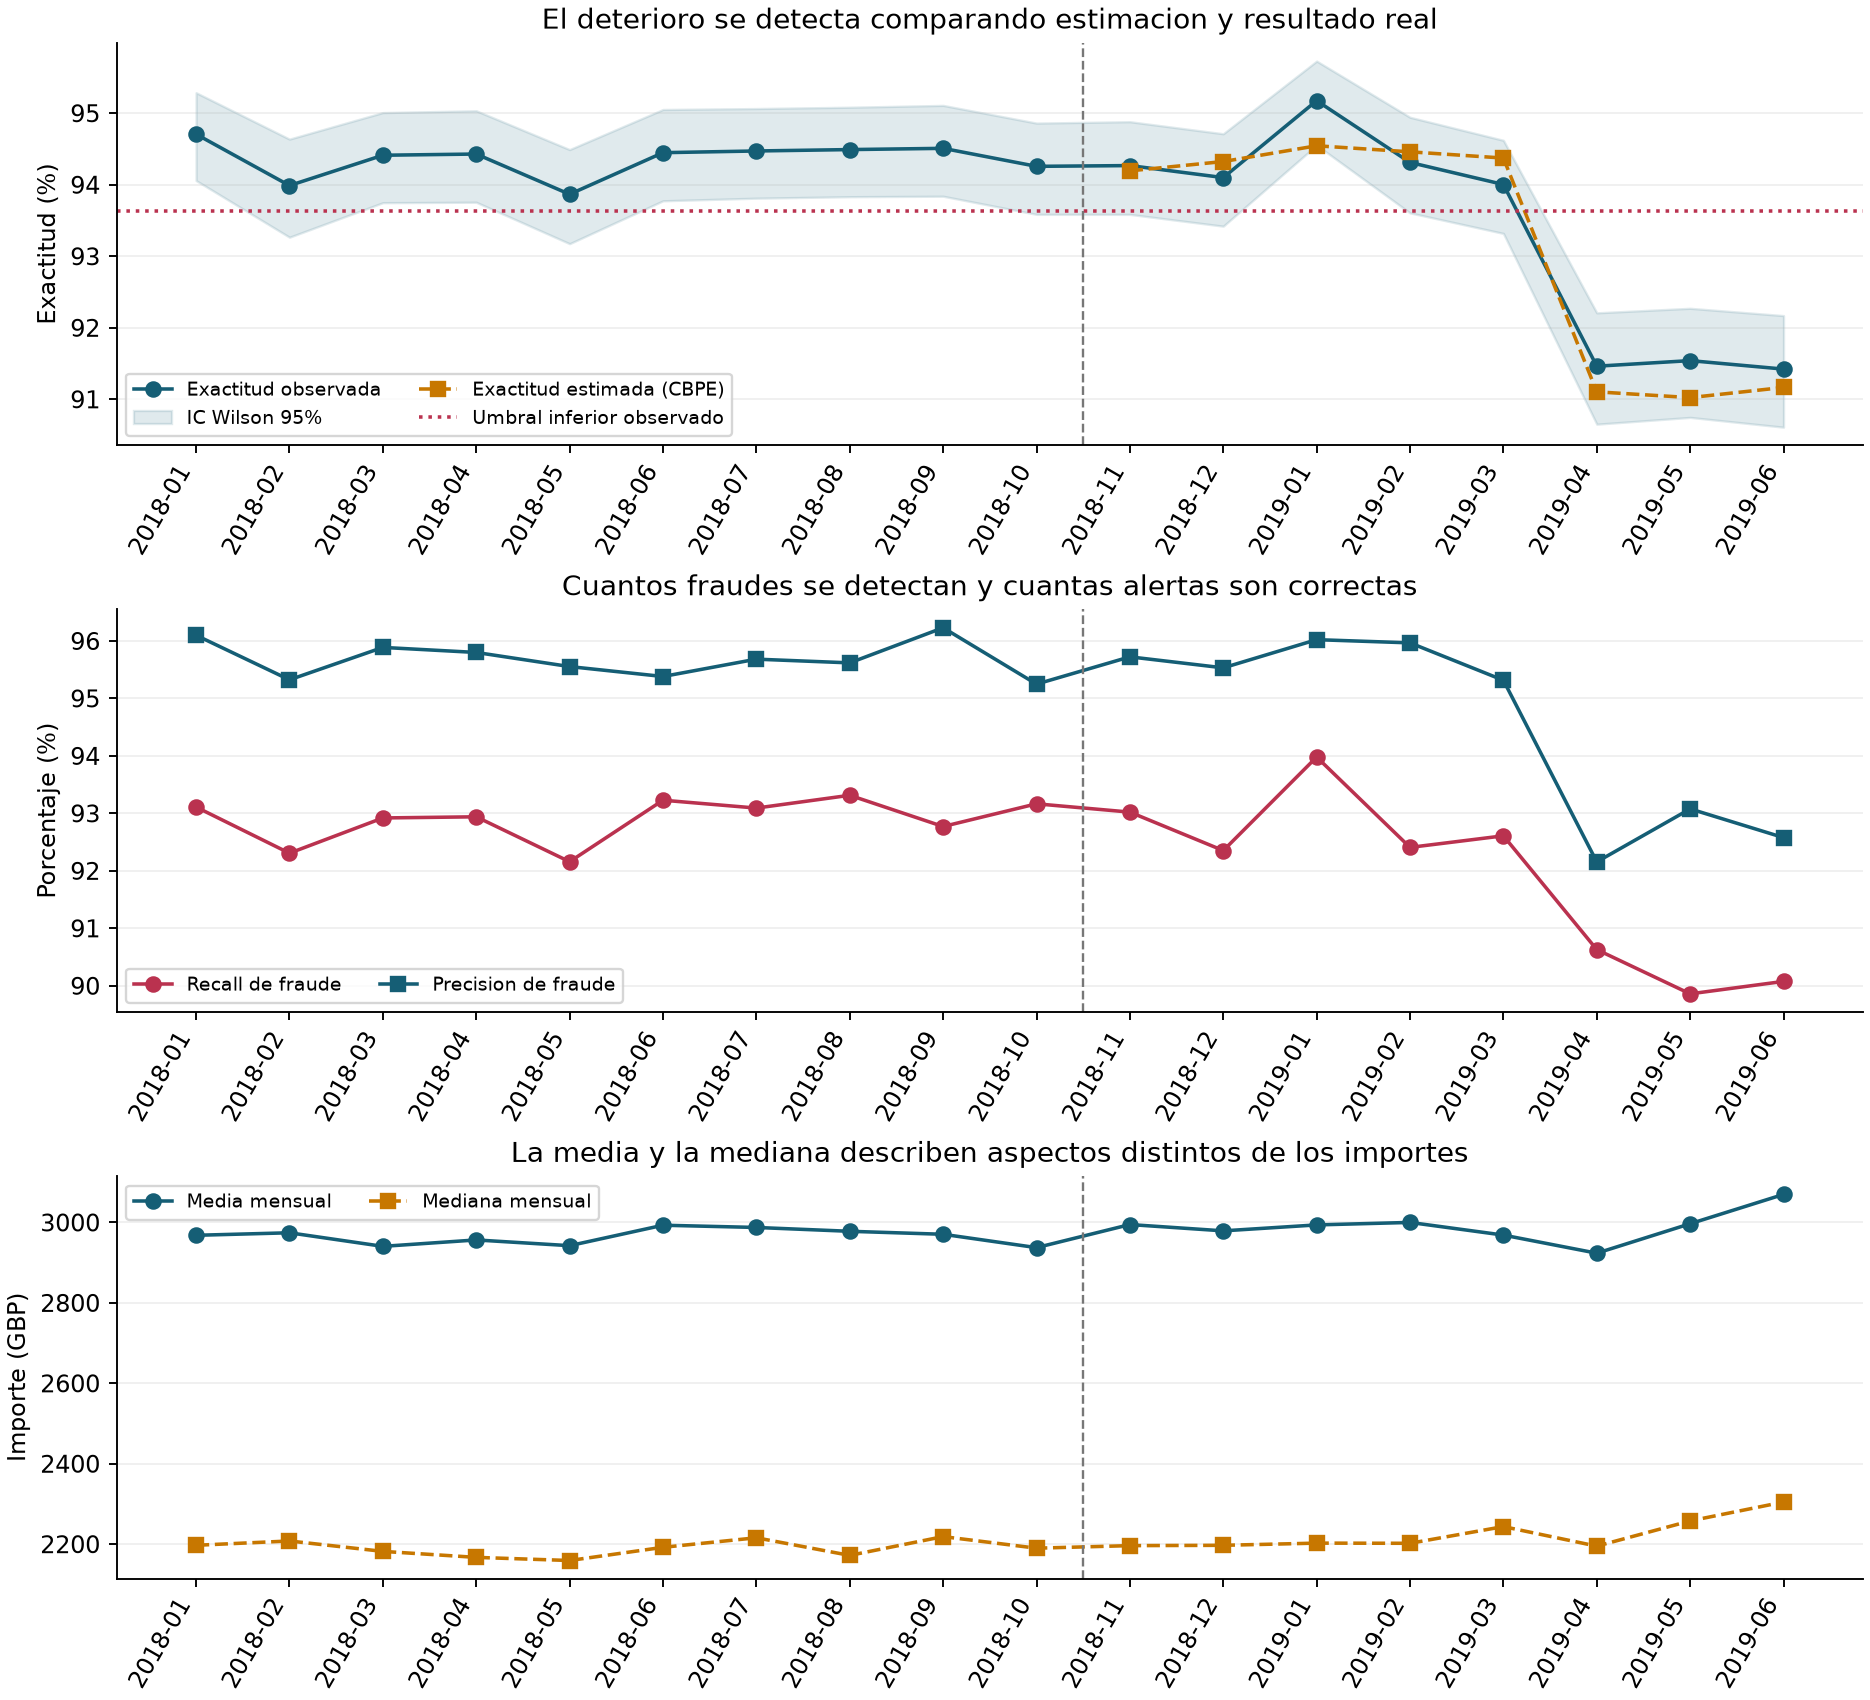

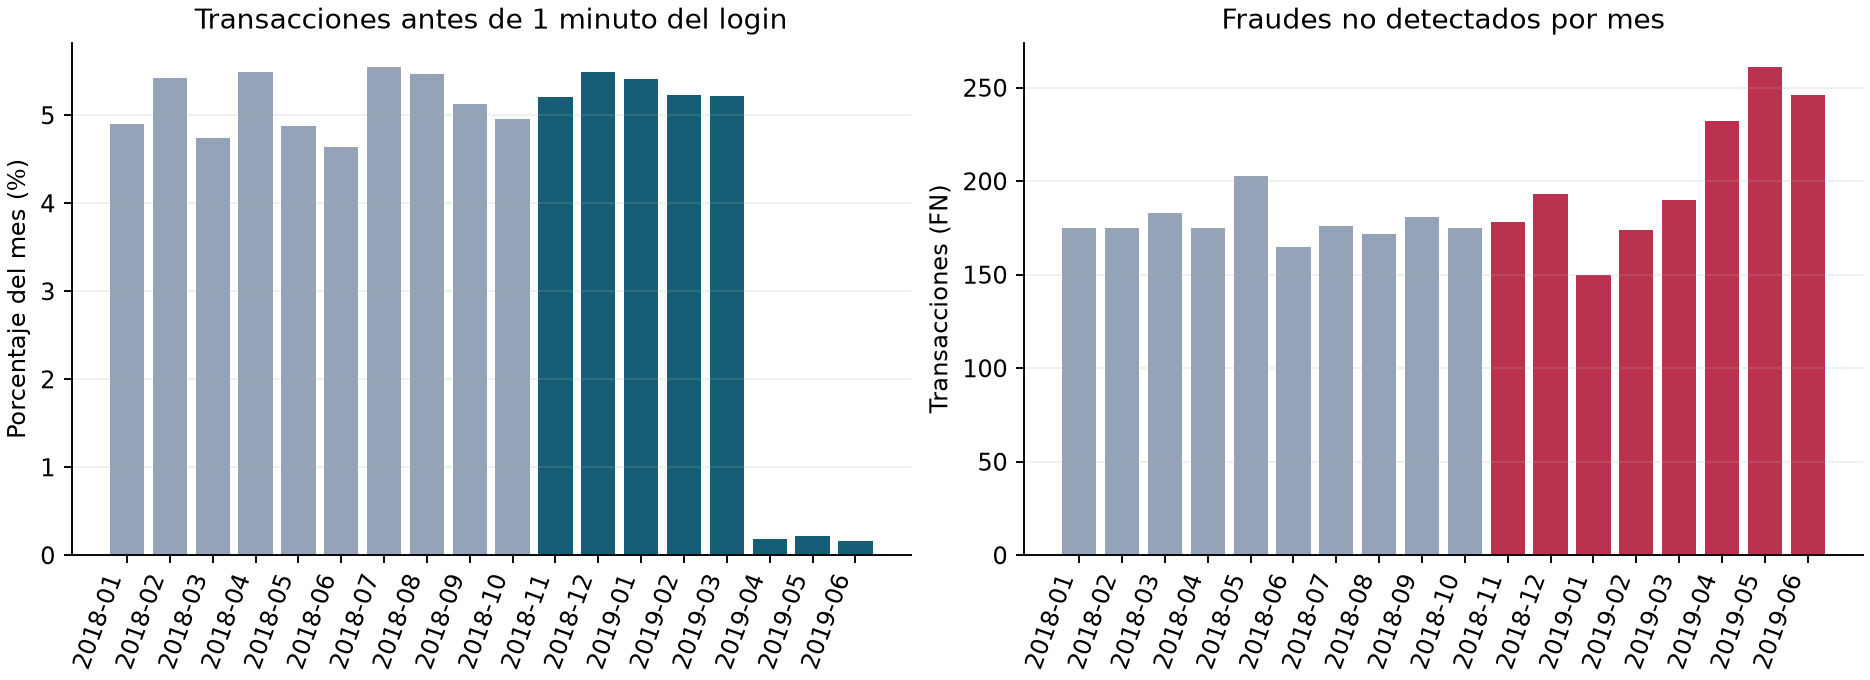

,phase,n,fraud_rate,error_rate,fn,fp,early_count,early_rate,amount_mean
0,produccion_alerta,15029,0.500965,0.085235,739,542,28,0.001863,2996.794700
1,produccion_estable,24938,0.498436,0.056260,885,518,1325,0.053132,2987.068217
2,referencia,50207,0.499751,0.056387,1780,1051,2569,0.051168,2964.744354


,phase,is_fraud,n,amount_mean,early_rate,login_mean
0,produccion_alerta,0,7500,2997.939759,0.001467,1.994334
1,produccion_alerta,1,7529,2995.654052,0.002258,1.988751
2,produccion_estable,0,12508,2932.237024,0.052207,1.927133
3,produccion_estable,1,12430,3042.243484,0.054063,1.920398
4,referencia,0,25116,2901.765886,0.050804,1.925881
5,referencia,1,25091,3027.785573,0.051532,1.927941


{
  "disagreements": {
    "0.5": 1889,
    "0.6": 730,
    "0.65": 0,
    "0.66": 148,
    "0.7": 854
  },
  "note": "0.65 reproduce las etiquetas suministradas. No se optimizo ni cambio el modelo."
}


In [6]:
def make_figures(monthly,perf,out):
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(3,1,figsize=(11,10),constrained_layout=True)
    x=np.arange(len(monthly)); prod=monthly.period.eq('analysis').to_numpy(); xp=x[prod]
    axes[0].plot(x,100*monthly.accuracy,'o-',label='Exactitud observada',color='#155e75')
    axes[0].fill_between(x,100*monthly.accuracy_ci_low,100*monthly.accuracy_ci_high,color='#155e75',alpha=.13,label='IC Wilson 95%')
    axes[0].plot(xp,100*perf.estimated_accuracy,'s--',label='Exactitud estimada (CBPE)',color='#c77700')
    axes[0].axhline(100*perf.realized_lower.iloc[0],ls=':',color='#ba324f',label='Umbral inferior observado')
    axes[0].set(ylabel='Exactitud (%)',title='El deterioro se detecta comparando estimacion y resultado real')
    axes[1].plot(x,100*monthly.recall,'o-',label='Recall de fraude',color='#ba324f')
    axes[1].plot(x,100*monthly.precision,'s-',label='Precision de fraude',color='#155e75')
    axes[1].set(ylabel='Porcentaje (%)',title='Cuantos fraudes se detectan y cuantas alertas son correctas')
    axes[2].plot(x,monthly.amount_mean,'o-',color='#155e75',label='Media mensual')
    axes[2].plot(x,monthly.amount_median,'s--',color='#c77700',label='Mediana mensual')
    axes[2].set(ylabel='Importe (GBP)',title='La media y la mediana describen aspectos distintos de los importes')
    for ax in axes:
        ax.axvline(xp[0]-.5,color='#777',ls='--',lw=1)
        ax.set_xticks(x,monthly.month,rotation=60,ha='right');ax.grid(axis='y',alpha=.2);ax.legend(fontsize=8,ncol=2)
    fig.savefig(out/'monitoring.png',dpi=170);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    axes[0].bar(x,100*monthly.login_under_1_rate,color=['#94a3b8' if not v else '#155e75' for v in prod])
    axes[0].set(title='Transacciones antes de 1 minuto del login',ylabel='Porcentaje del mes (%)')
    axes[1].bar(x,monthly.fn,color=['#94a3b8' if not v else '#ba324f' for v in prod])
    axes[1].set(title='Fraudes no detectados por mes',ylabel='Transacciones (FN)')
    for ax in axes:
        ax.set_xticks(x,monthly.month,rotation=70,ha='right');ax.grid(axis='y',alpha=.2)
    fig.savefig(out/'diagnosis.png',dpi=170);plt.close(fig)

make_figures(monthly,performance,output/'final')
display(Image(filename=str(output/'final/monitoring.png')))
display(Image(filename=str(output/'final/diagnosis.png')))
display(pd.read_csv(output/'final/phase_summary.csv'))
display(pd.read_csv(output/'final/segments.csv'))
print((output/'final/prediction_threshold_check.json').read_text(encoding='utf8'))

## 7. Entrega de las variables solicitadas
La media del mes con alerta no es el límite de alerta. El código exige un único mes de importe alertado
antes de asignar el escalar. Las respuestas se extraen de los cálculos, sin prefijar su valor.

In [7]:
months_with_performance_alerts=final['months_with_performance_alerts']
highest_correlation_feature=final['highest_correlation_feature']
alert_avg_transaction_amount=final['alert_avg_transaction_amount']
print('months_with_performance_alerts =',months_with_performance_alerts)
print('highest_correlation_feature =',highest_correlation_feature)
print('alert_avg_transaction_amount =',alert_avg_transaction_amount)
versions={'python':platform.python_version()}
for package in ['nannyml','pandas','numpy','scipy','scikit-learn','matplotlib','statsmodels','category-encoders']:
    versions[package]=metadata.version(package)
save_json(output/'versions.json',versions)
display(versions)

months_with_performance_alerts = ['april_2019', 'may_2019', 'june_2019']
highest_correlation_feature = time_since_login_min
alert_avg_transaction_amount = 3069.8184


{'python': '3.11.9',
 'nannyml': '0.13.1',
 'pandas': '2.2.3',
 'numpy': '1.26.4',
 'scipy': '1.14.1',
 'scikit-learn': '1.5.2',
 'matplotlib': '3.11.2',
 'statsmodels': '0.14.4',
 'category-encoders': '2.6.4'}

## 8. Interpretación y próximos pasos
La alerta conjunta aparece en abril, mayo y junio de 2019. `time_since_login_min` encabeza el ranking.
El importe medio de junio es £3.069,8184; el límite superior aprendido es £3.021,4111.
La exactitud agregada cae de 94,37 % en producción estable a 91,48 % durante los tres meses de alerta.

Las operaciones antes de un minuto caen de 5,31 % a 0,19 %, pero no desaparecen: quedan 28.
El cambio afecta a ambas clases. No permite concluir que los estafadores hayan aprendido a eludir el sistema.
Se deben investigar la captura del login, cambios en la aplicación y composición de transacciones.
El Pearson fuerte, con Spearman débil y ocho meses, sugiere principalmente un cambio de régimen.

Se recomienda vigilar recall, precisión, calidad y calibración, revisar los errores y probar mejoras
del detector en una validación temporal futura. No hay modelo entrenado ni costes reales para certificar
reentrenamiento o ahorro. Los importes FN son exposición del dataset, no pérdidas confirmadas.

### Fuentes metodológicas
- [NannyML: CBPE y sus supuestos](https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html)
- [NannyML: CorrelationRanker](https://nannyml.readthedocs.io/en/stable/_modules/nannyml/drift/ranker.html)
- [NannyML: medias](https://nannyml.readthedocs.io/en/main/tutorials/summary_stats/avg.html)

El informe PDF incluye el contexto, la comparación entre pruebas, resultados, limitaciones y propuestas.
La solución fue aprobada por el corrector de DataCamp el 9 de noviembre de 2026. La evidencia se conserva en `evidence/datacamp_aprobado.jpg`. Las verificaciones locales y la aprobación del ejercicio tienen alcances distintos: el corrector valida las respuestas solicitadas, mientras que la ampliación documenta el diagnóstico y sus límites.